# Freight Rate Prediction Pipeline

End-to-end regression pipeline for predicting posted_rate on U.S. truckload freight loads.
- **Data**: 48,000 labeled loads (train-test.csv, Jan 1 – Oct 31, 2025)
- **Target**: posted_rate (continuous regression)
- **Validation**: Chronological holdout split (Sep 1 – Oct 31, 2025)
- **Model**: HistGradientBoostingRegressor with MAE loss (loss='absolute_error')
- **Scoring**: 12,000 loads (validation.csv) + 31 daily fixed-lane loads (december-chart-inputs.csv)

In [1]:
import math
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Plotting aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10

# Paths
ROOT = Path(".").resolve()
TRAIN_PATH = ROOT / "train-test.csv"
VALIDATION_PATH = ROOT / "validation.csv"
TEMPLATE_PATH = ROOT / "validation-predictions-template.csv"
DECEMBER_TEMPLATE_PATH = ROOT / "december-chart-inputs.csv"
PRED_PATH = ROOT / "validation_predictions.csv"
DECEMBER_PRED_PATH = ROOT / "december_chart_predictions.csv"
SCORER_DIR = ROOT / "scorer_results"

SCORER_DIR.mkdir(exist_ok=True)

# Feature definitions
CAT_FEATURES = ["equipment", "pickup", "delivery"]
ENGINEERED_CATS = ["lane"]
NUM_FEATURES = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "month",
    "dayofweek",
    "is_weekend",
    "doy_sin",
    "doy_cos",
    "quote_x_distance",
    "market_x_distance",
    "weight_missing",
    "market_missing",
]
MODEL_FEATURES = NUM_FEATURES + CAT_FEATURES
print("Pipeline configuration loaded successfully.")

Pipeline configuration loaded successfully.


## 1. Load Data

In [2]:
def load_labeled() -> pd.DataFrame:
    df = pd.read_csv(TRAIN_PATH)
    df["date"] = pd.to_datetime(df["date"])
    return df

def load_validation() -> pd.DataFrame:
    df = pd.read_csv(VALIDATION_PATH)
    df["date"] = pd.to_datetime(df["date"])
    return df

df = load_labeled()
print(f"Loaded labeled data: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date span: {df['date'].min().date()} to {df['date'].max().date()}")
df.head()

Loaded labeled data: 48,000 rows, 14 columns
Date span: 2025-01-01 to 2025-10-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## 2. Inspect Data & Summary Stats

In [3]:
def explore(df: pd.DataFrame) -> dict:
    print("=" * 72)
    print("DATASET INSPECTION & SUMMARY")
    print("=" * 72)
    print(f"Dataset Shape: {df.shape}")
    print("\n--- Column Info ---")
    df.info()
    print("\n--- Numerical & Categorical Summary ---")
    print(df.describe(include="all").transpose())
    print("\n--- Missing Values Count ---")
    missing = df.isna().sum()
    print(missing[missing > 0])
    print("\n--- Unique Values Count ---")
    print(df.nunique())
    print("\n--- Target Variable (posted_rate) Distribution ---")
    print(df["posted_rate"].describe())
    print("Skewness:", round(df["posted_rate"].skew(), 3))
    return {
        "n_rows": int(len(df)),
        "n_cols": int(df.shape[1]),
        "weight_missing": int(missing.get("weight", 0)),
        "market_missing": int(missing.get("market_index", 0)),
        "rate_mean": float(df["posted_rate"].mean()),
        "rate_std": float(df["posted_rate"].std()),
        "rate_min": float(df["posted_rate"].min()),
        "rate_max": float(df["posted_rate"].max()),
        "rate_skew": float(df["posted_rate"].skew()),
        "date_min": str(df["date"].min().date()),
        "date_max": str(df["date"].max().date()),
    }

explore_stats = explore(df)

DATASET INSPECTION & SUMMARY
Dataset Shape: (48000, 14)

--- Column Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   load_id       48000 non-null  object        
 1   pickup        48000 non-null  object        
 2   delivery      48000 non-null  object        
 3   pickup_lat    48000 non-null  float64       
 4   pickup_lon    48000 non-null  float64       
 5   delivery_lat  48000 non-null  float64       
 6   delivery_lon  48000 non-null  float64       
 7   distance      48000 non-null  float64       
 8   equipment     48000 non-null  object        
 9   weight        47700 non-null  float64       
 10  date          48000 non-null  datetime64[ns]
 11  market_index  47626 non-null  float64       
 12  quote_signal  48000 non-null  float64       
 13  posted_rate   48000 non-null  float64       
dtypes: dateti

## 3. Missing Value Analysis
weight and market_index are the only incomplete columns.
- weight is missing in ~300 training loads; trailer equipment types have distinct payload profiles.
- market_index is missing in ~374 training loads and has monthly seasonality.

In [4]:
print("Missing weight by equipment type:")
print(df.groupby("equipment")["weight"].apply(lambda s: s.isna().sum()))

print("\nMissing market_index by calendar month:")
print(df.assign(month=df["date"].dt.month).groupby("month")["market_index"].apply(lambda s: s.isna().sum()))

Missing weight by equipment type:
equipment
Dry Van    175
Flatbed     55
Reefer      70
Name: weight, dtype: int64

Missing market_index by calendar month:
month
1     36
2     36
3     44
4     31
5     43
6     42
7     36
8     33
9     31
10    42
Name: market_index, dtype: int64


## 4. Exploratory Data Analysis & Correlations
Check linear and rank correlations against posted_rate and Rate Per Mile (RPM = 
ate / distance).

CORRELATION ANALYSIS
Pearson Correlation vs posted_rate:
posted_rate     1.000000
distance        0.908519
delivery_lon   -0.257086
pickup_lon     -0.255058
delivery_lat   -0.091970
pickup_lat     -0.090873
quote_signal   -0.039858
weight          0.034840
market_index    0.034165
Name: posted_rate, dtype: float64

Spearman Correlation vs posted_rate:
posted_rate     1.000000
distance        0.975969
delivery_lon   -0.199305
pickup_lon     -0.196526
delivery_lat   -0.114916
pickup_lat     -0.112080
weight          0.041676
quote_signal   -0.039912
market_index    0.031505
Name: posted_rate, dtype: float64

quote_signal vs Rate Per Mile (RPM): 0.0493
market_index vs Rate Per Mile (RPM): 0.0835
weight vs posted_rate: 0.0349
weight vs RPM: 0.0742
quote_signal * distance vs posted_rate: 0.8987


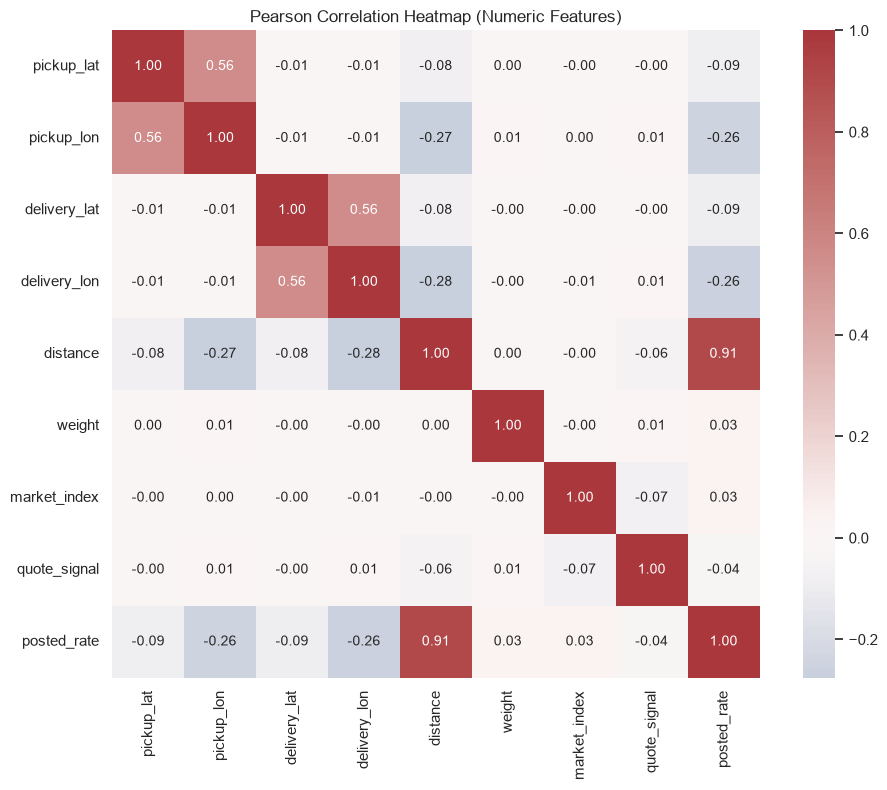

C:\Users\HP\AppData\Local\Temp\ipykernel_10632\86960841.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tmp, x="equipment", y="posted_rate", ax=axes[0], palette="Blues_d")
C:\Users\HP\AppData\Local\Temp\ipykernel_10632\86960841.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tmp, x="equipment", y="rpm", ax=axes[1], palette="Blues_d")


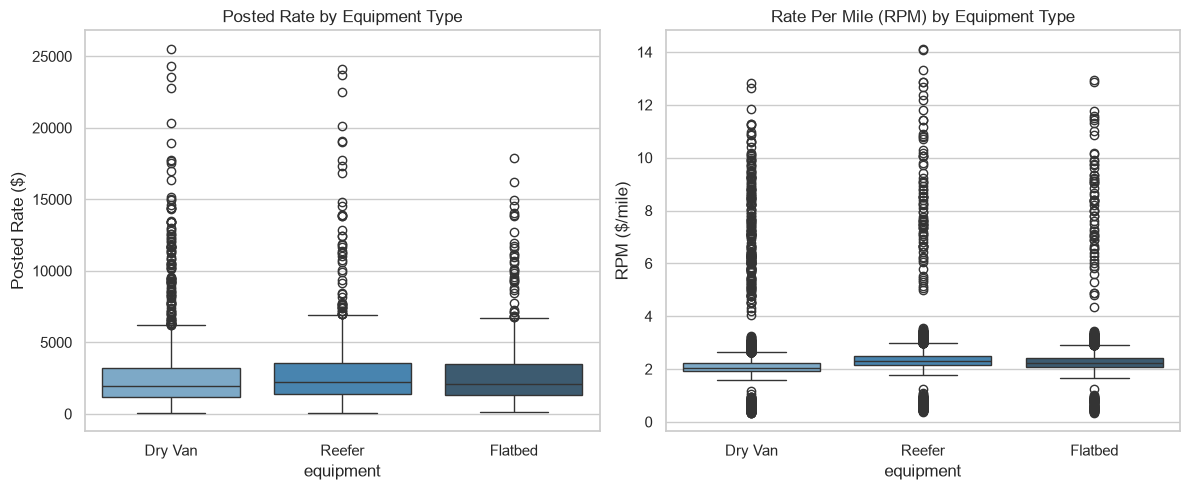

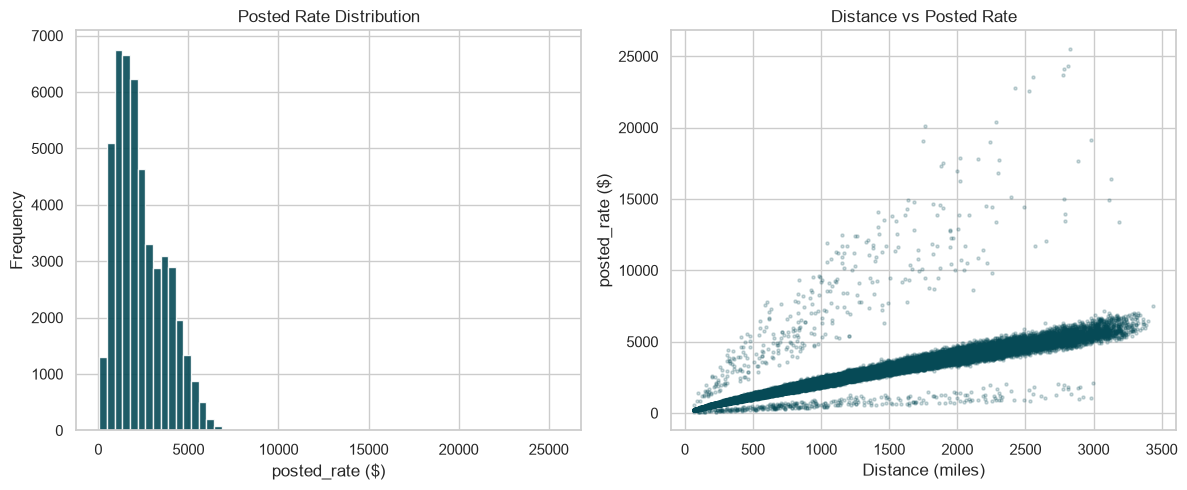

In [5]:
def correlation_analysis(df: pd.DataFrame) -> None:
    print("=" * 72)
    print("CORRELATION ANALYSIS")
    print("=" * 72)
    numeric = df.select_dtypes(include=[np.number])
    pearson = numeric.corr(method="pearson")
    spearman = numeric.corr(method="spearman")
    print("Pearson Correlation vs posted_rate:")
    print(pearson["posted_rate"].sort_values(key=np.abs, ascending=False))
    print("\nSpearman Correlation vs posted_rate:")
    print(spearman["posted_rate"].sort_values(key=np.abs, ascending=False))

    rpm = df["posted_rate"] / df["distance"]
    complete = df.dropna(subset=["weight", "market_index"]).copy()
    complete["rpm"] = complete["posted_rate"] / complete["distance"]
    print("\nquote_signal vs Rate Per Mile (RPM):", round(np.corrcoef(df["quote_signal"], rpm)[0, 1], 4))
    print("market_index vs Rate Per Mile (RPM):", round(complete[["market_index", "rpm"]].corr().iloc[0, 1], 4))
    print("weight vs posted_rate:", round(complete[["weight", "posted_rate"]].corr().iloc[0, 1], 4))
    print("weight vs RPM:", round(complete[["weight", "rpm"]].corr().iloc[0, 1], 4))
    print("quote_signal * distance vs posted_rate:", round(np.corrcoef(df["quote_signal"] * df["distance"], df["posted_rate"])[0, 1], 4))

    # Figure 1: Pearson correlation heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(pearson, cmap="vlag", center=0, annot=True, fmt=".2f", square=True)
    plt.title("Pearson Correlation Heatmap (Numeric Features)")
    plt.tight_layout()
    plt.show()

    # Figure 2: Equipment vs Posted Rate & RPM
    tmp = df.copy()
    tmp["rpm"] = tmp["posted_rate"] / tmp["distance"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.boxplot(data=tmp, x="equipment", y="posted_rate", ax=axes[0], palette="Blues_d")
    axes[0].set_title("Posted Rate by Equipment Type")
    axes[0].set_ylabel("Posted Rate ($)")
    sns.boxplot(data=tmp, x="equipment", y="rpm", ax=axes[1], palette="Blues_d")
    axes[1].set_title("Rate Per Mile (RPM) by Equipment Type")
    axes[1].set_ylabel("RPM ($/mile)")
    plt.tight_layout()
    plt.show()

    # Figure 3: Rate Distribution & Distance vs Rate Scatter
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].hist(df["posted_rate"], bins=60, color="#064A56", edgecolor="white", alpha=0.9)
    axes[0].set_title("Posted Rate Distribution")
    axes[0].set_xlabel("posted_rate ($)")
    axes[0].set_ylabel("Frequency")
    axes[1].scatter(df["distance"], df["posted_rate"], s=5, alpha=0.2, color="#064A56")
    axes[1].set_title("Distance vs Posted Rate")
    axes[1].set_xlabel("Distance (miles)")
    axes[1].set_ylabel("posted_rate ($)")
    plt.tight_layout()
    plt.show()

correlation_analysis(df)

## 5. Feature Engineering & Preprocessor
- Impute weight with equipment medians; impute market_index with monthly medians; add missing indicators.
- Cyclical day-of-year features (sin/cos), day-of-week, and weekend flag.
- Mileage interactions: quote_signal * distance and market_index * distance.
- Winsorize training target at 99th percentile to curb outlier leverage.
- Preserve all original columns including load_id (excluded from model features).

In [6]:
class RatePreprocessor:
    """Imputes missing values, encodes cyclical time features, engineers domain interactions.
    Preserves all original columns, including load_id.
    """

    def __init__(self) -> None:
        self.weight_medians_: dict[str, float] = {}
        self.weight_global_: float = 0.0
        self.market_month_medians_: dict[int, float] = {}
        self.market_global_: float = 0.0
        self.rate_cap_: float = np.inf
        self.pickup_coords_: pd.DataFrame | None = None
        self.delivery_coords_: pd.DataFrame | None = None
        self.categories_: dict[str, list] = {}

    def fit(self, df: pd.DataFrame) -> "RatePreprocessor":
        self.weight_medians_ = df.groupby("equipment")["weight"].median().to_dict()
        self.weight_global_ = float(df["weight"].median())
        months = df["date"].dt.month
        self.market_month_medians_ = (
            df.assign(month=months).groupby("month")["market_index"].median().to_dict()
        )
        self.market_global_ = float(df["market_index"].median())
        self.rate_cap_ = float(df["posted_rate"].quantile(0.99))
        self.pickup_coords_ = (
            df.groupby("pickup")[["pickup_lat", "pickup_lon"]].median().reset_index()
        )
        self.delivery_coords_ = (
            df.groupby("delivery")[["delivery_lat", "delivery_lon"]].median().reset_index()
        )
        tmp = self._add_derived(df.copy(), fit_categories=False)
        for col in CAT_FEATURES + ENGINEERED_CATS:
            self.categories_[col] = sorted(tmp[col].dropna().astype(str).unique().tolist())
        print("RatePreprocessor fitted successfully:")
        print(f" - Weight medians by equipment: {self.weight_medians_}")
        print(f" - Market medians by month: {{m: round(v, 4) for m, v in self.market_month_medians_.items()}}")
        print(f" - 99th percentile rate cap: ${self.rate_cap_:,.2f}")
        return self

    def _add_derived(self, df: pd.DataFrame, fit_categories: bool) -> pd.DataFrame:
        df = df.copy()
        df["date"] = pd.to_datetime(df["date"])
        df["weight_missing"] = df["weight"].isna().astype(int)
        df["market_missing"] = df["market_index"].isna().astype(int)

        def fill_weight(row: pd.Series) -> float:
            if pd.notna(row["weight"]):
                return float(row["weight"])
            return float(self.weight_medians_.get(row["equipment"], self.weight_global_))

        def fill_market(row: pd.Series) -> float:
            if pd.notna(row["market_index"]):
                return float(row["market_index"])
            month = int(pd.Timestamp(row["date"]).month)
            return float(self.market_month_medians_.get(month, self.market_global_))

        df["weight"] = df.apply(fill_weight, axis=1)
        df["market_index"] = df.apply(fill_market, axis=1)

        doy = df["date"].dt.dayofyear.astype(float)
        df["month"] = df["date"].dt.month.astype(int)
        df["dayofweek"] = df["date"].dt.dayofweek.astype(int)
        df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
        df["doy_sin"] = np.sin(2 * math.pi * doy / 365.25)
        df["doy_cos"] = np.cos(2 * math.pi * doy / 365.25)

        df["quote_x_distance"] = df["quote_signal"] * df["distance"]
        df["market_x_distance"] = df["market_index"] * df["distance"]
        df["lane"] = df["pickup"].astype(str) + " -> " + df["delivery"].astype(str)

        if fit_categories:
            for col in CAT_FEATURES + ENGINEERED_CATS:
                cats = self.categories_.get(col)
                df[col] = pd.Categorical(df[col].astype(str), categories=cats)
        return df

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        return self._add_derived(df, fit_categories=True)

    def cap_target(self, y: pd.Series) -> pd.Series:
        return y.clip(upper=self.rate_cap_)

## 6. Chronological Train / Holdout Split
Split by date (Jan–Aug train, Sep–Oct holdout) to prevent future data leakage.

In [7]:
def time_split(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    train = df[df["date"] < "2025-09-01"].copy()
    holdout = df[df["date"] >= "2025-09-01"].copy()
    print("=" * 72)
    print("CHRONOLOGICAL TRAIN / HOLDOUT SPLIT")
    print("=" * 72)
    print(f"Training split (Jan 1 - Aug 31): {len(train):,} loads ({len(train)/len(df)*100:.1f}%)")
    print(f"Holdout split (Sep 1 - Oct 31):  {len(holdout):,} loads ({len(holdout)/len(df)*100:.1f}%)")
    return train, holdout

train_raw, holdout_raw = time_split(df)
split_pre = RatePreprocessor().fit(train_raw)
train = split_pre.transform(train_raw)
holdout = split_pre.transform(holdout_raw)

print(f"\nIntegrity Checks:")
print(f" - All original columns preserved: {all(c in train.columns for c in df.columns)}")
print(f" - load_id present in DataFrame: {'load_id' in train.columns}")
print(f" - Missing values in train after imputation: {train[['weight', 'market_index']].isna().sum().to_dict()}")
print(f" - Missing values in holdout after imputation: {holdout[['weight', 'market_index']].isna().sum().to_dict()}")

CHRONOLOGICAL TRAIN / HOLDOUT SPLIT
Training split (Jan 1 - Aug 31): 38,477 loads (80.2%)
Holdout split (Sep 1 - Oct 31):  9,523 loads (19.8%)
RatePreprocessor fitted successfully:
 - Weight medians by equipment: {'Dry Van': 31355.0, 'Flatbed': 31453.0, 'Reefer': 31485.0}
 - Market medians by month: {m: round(v, 4) for m, v in self.market_month_medians_.items()}
 - 99th percentile rate cap: $5,968.61

Integrity Checks:
 - All original columns preserved: True
 - load_id present in DataFrame: True
 - Missing values in train after imputation: {'weight': 0, 'market_index': 0}
 - Missing values in holdout after imputation: {'weight': 0, 'market_index': 0}


## 7. Model Training & Holdout Evaluation
Benchmark Ridge baseline against HistGradientBoostingRegressor (loss='absolute_error').
Metrics: MAE, RMSE, MAPE, R².

HOLDOUT EVALUATION (TRAIN: JAN-AUG, HOLDOUT: SEP-OCT)

Holdout Performance Comparison:
Ridge Linear Baseline     MAE: $183.47  |  RMSE: $656.55  |  MAPE: 9.22%  |  R2: 0.8149
HistGradientBoosting      MAE: $126.97  |  RMSE: $640.52  |  MAPE: 5.35%  |  R2: 0.8238

HistGB trees converged at iteration: 500


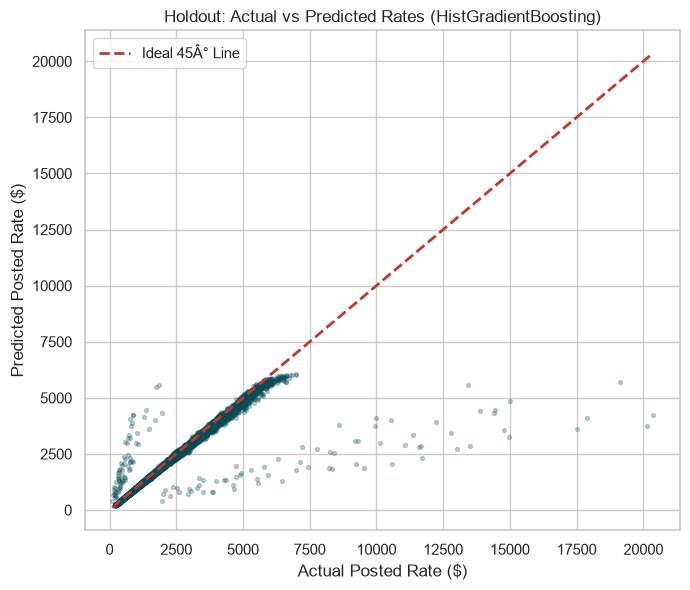

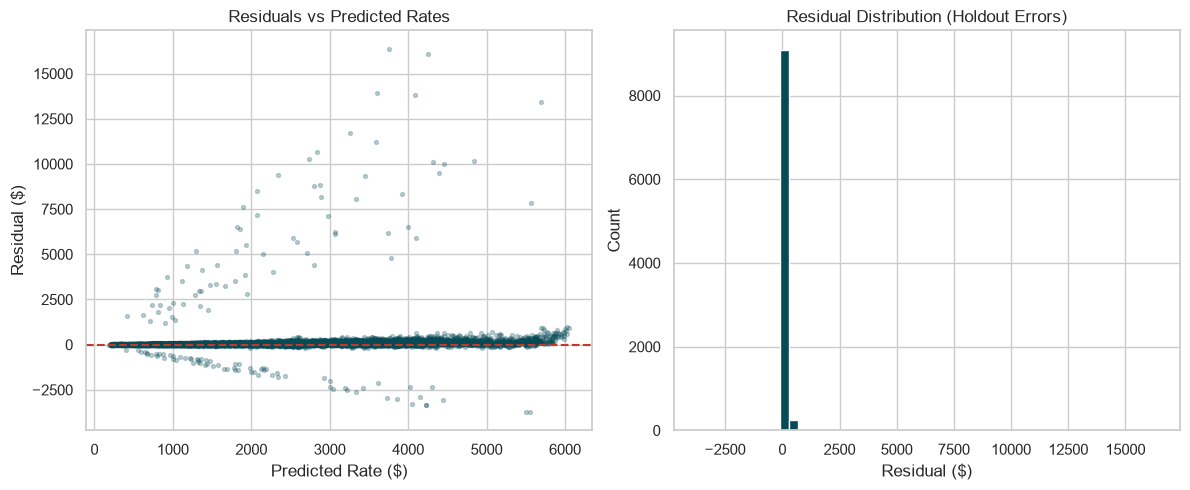

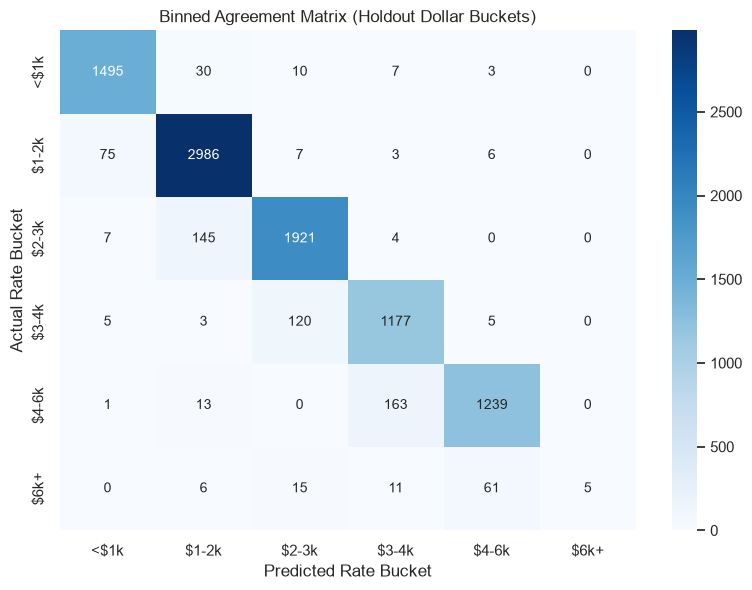


Binned Agreement Matrix:
Predicted Rate Bucket  <$1k  $1-2k  $2-3k  $3-4k  $4-6k  $6k+
Actual Rate Bucket                                           
<$1k                   1495     30     10      7      3     0
$1-2k                    75   2986      7      3      6     0
$2-3k                     7    145   1921      4      0     0
$3-4k                     5      3    120   1177      5     0
$4-6k                     1     13      0    163   1239     0
$6k+                      0      6     15     11     61     5


In [8]:
def metrics_dict(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    mae = float(mean_absolute_error(y_true, y_pred))
    rmse = float(math.sqrt(mean_squared_error(y_true, y_pred)))
    mape = float(np.mean(np.abs((y_true - y_pred) / np.clip(y_true, 1e-6, None))) * 100)
    r2 = float(r2_score(y_true, y_pred))
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "R2": r2}

def print_metrics(name: str, stats: dict[str, float]) -> None:
    print(
        f"{name:24s}  MAE: ${stats['MAE']:.2f}  |  RMSE: ${stats['RMSE']:.2f}  |  "
        f"MAPE: {stats['MAPE']:.2f}%  |  R2: {stats['R2']:.4f}"
    )

def build_histgb() -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(
        loss="absolute_error",
        learning_rate=0.06,
        max_depth=8,
        max_iter=500,
        min_samples_leaf=40,
        l2_regularization=0.1,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
        categorical_features="from_dtype",
    )

def build_ridge() -> Pipeline:
    ridge_num = ["distance", "quote_x_distance", "market_x_distance", "weight", "market_index"]
    ridge_cat = ["equipment"]
    pre = ColumnTransformer(
        [
            ("num", StandardScaler(), ridge_num),
            ("cat", OneHotEncoder(handle_unknown="ignore"), ridge_cat),
        ]
    )
    return Pipeline(
        [
            ("pre", pre),
            ("model", Ridge(alpha=1.0)),
        ]
    )

def model_matrix(df: pd.DataFrame) -> pd.DataFrame:
    X = df[MODEL_FEATURES].copy()
    for col in CAT_FEATURES:
        X[col] = df[col]
    return X

def evaluate_holdout(train: pd.DataFrame, holdout: pd.DataFrame, pre: RatePreprocessor) -> dict:
    print("=" * 72)
    print("HOLDOUT EVALUATION (TRAIN: JAN-AUG, HOLDOUT: SEP-OCT)")
    print("=" * 72)
    X_train = model_matrix(train)
    y_train = pre.cap_target(train["posted_rate"])
    X_hold = model_matrix(holdout)
    y_hold = holdout["posted_rate"].to_numpy()

    # Baseline Ridge
    ridge = build_ridge()
    ridge.fit(train, y_train)
    ridge_pred = np.clip(ridge.predict(holdout), 1.0, None)
    ridge_stats = metrics_dict(y_hold, ridge_pred)

    # HistGradientBoosting
    histgb = build_histgb()
    histgb.fit(X_train, y_train)
    hist_pred = np.clip(histgb.predict(X_hold), 1.0, None)
    hist_stats = metrics_dict(y_hold, hist_pred)

    print("\nHoldout Performance Comparison:")
    print_metrics("Ridge Linear Baseline", ridge_stats)
    print_metrics("HistGradientBoosting", hist_stats)
    print(f"\nHistGB trees converged at iteration: {histgb.n_iter_}")

    # Plot 1: Actual vs Predicted
    plt.figure(figsize=(7, 6))
    plt.scatter(y_hold, hist_pred, s=8, alpha=0.25, color="#064A56")
    lo = min(y_hold.min(), hist_pred.min())
    hi = max(y_hold.max(), hist_pred.max())
    plt.plot([lo, hi], [lo, hi], color="#C0392B", linewidth=2, linestyle="--", label="Ideal 45Â° Line")
    plt.xlabel("Actual Posted Rate ($)")
    plt.ylabel("Predicted Posted Rate ($)")
    plt.title("Holdout: Actual vs Predicted Rates (HistGradientBoosting)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Plot 2: Residual Analysis
    resid = y_hold - hist_pred
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(hist_pred, resid, s=8, alpha=0.25, color="#064A56")
    axes[0].axhline(0, color="#C0392B", linestyle="--")
    axes[0].set_title("Residuals vs Predicted Rates")
    axes[0].set_xlabel("Predicted Rate ($)")
    axes[0].set_ylabel("Residual ($)")
    axes[1].hist(resid, bins=50, color="#064A56", edgecolor="white")
    axes[1].set_title("Residual Distribution (Holdout Errors)")
    axes[1].set_xlabel("Residual ($)")
    axes[1].set_ylabel("Count")
    plt.tight_layout()
    plt.show()

    # Plot 3: Binned Agreement Table
    bins = [0, 1000, 2000, 3000, 4000, 6000, np.inf]
    labels = ["<$1k", "$1-2k", "$2-3k", "$3-4k", "$4-6k", "$6k+"]
    actual_b = pd.cut(y_hold, bins=bins, labels=labels, right=False)
    pred_b = pd.cut(hist_pred, bins=bins, labels=labels, right=False)
    cm = pd.crosstab(actual_b, pred_b, rownames=["Actual Rate Bucket"], colnames=["Predicted Rate Bucket"])
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title("Binned Agreement Matrix (Holdout Dollar Buckets)")
    plt.tight_layout()
    plt.show()
    print("\nBinned Agreement Matrix:")
    print(cm)

    return {
        "ridge": ridge_stats,
        "histgb": hist_stats,
        "n_iter": int(histgb.n_iter_),
        "rate_cap": float(pre.rate_cap_),
        "n_train": int(len(train)),
        "n_holdout": int(len(holdout)),
    }

model_stats = evaluate_holdout(train, holdout, split_pre)

*Note on evaluation: posted_rate is a continuous monetary target, so we evaluate standard regression metrics (MAE/RMSE/MAPE/R²). The binned matrix is a diagnostic visualization of dollar-tier agreement.*

## 8. Refit on Full Labeled Dataset
Refit preprocessor and HistGB on all 48,000 labeled loads (Jan–Oct) before generating submission predictions.

In [9]:
def fit_final(labeled: pd.DataFrame, pre: RatePreprocessor) -> HistGradientBoostingRegressor:
    print("=" * 72)
    print("REFITTING MODEL ON ALL 48,000 LABELED LOADS")
    print("=" * 72)
    X = model_matrix(labeled)
    y = pre.cap_target(labeled["posted_rate"])
    model = build_histgb()
    model.fit(X, y)
    print(f"Final HistGB model refit completed in {model.n_iter_} iterations.")
    return model

def predict_rates(model: HistGradientBoostingRegressor, df: pd.DataFrame) -> np.ndarray:
    return np.clip(model.predict(model_matrix(df)), 1.0, None)

final_pre = RatePreprocessor().fit(df)
labeled_prep = final_pre.transform(df)
model = fit_final(labeled_prep, final_pre)

RatePreprocessor fitted successfully:
 - Weight medians by equipment: {'Dry Van': 31373.0, 'Flatbed': 31462.5, 'Reefer': 31524.0}
 - Market medians by month: {m: round(v, 4) for m, v in self.market_month_medians_.items()}
 - 99th percentile rate cap: $5,972.83
REFITTING MODEL ON ALL 48,000 LABELED LOADS
Final HistGB model refit completed in 500 iterations.


In [10]:
import joblib
joblib.dump(model, ROOT / "model.joblib")
print(f"Saved model artifacts to disk: {model}")

Saved model artifacts to disk: HistGradientBoostingRegressor(early_stopping=True, l2_regularization=0.1,
                              learning_rate=0.06, loss='absolute_error',
                              max_depth=8, max_iter=500, min_samples_leaf=40,
                              n_iter_no_change=20, random_state=42)


## 9. Validation Predictions (validation_predictions.csv)
Generate predictions for 


validation.csv (12,000 loads) formatted as load_id,predicted_rate.

In [11]:
def write_validation_predictions(model: HistGradientBoostingRegressor, pre: RatePreprocessor) -> pd.DataFrame:
    print("=" * 72)
    print("GENERATING VALIDATION SET PREDICTIONS (12,000 ROWS)")
    print("=" * 72)
    raw = load_validation()
    print(f"Validation dataset: {raw.shape[0]:,} loads, dates {raw['date'].min().date()} to {raw['date'].max().date()}")
    print("Missing columns in validation:\n", raw.isna().sum()[raw.isna().sum() > 0])

    prepared = pre.transform(raw)
    preds = predict_rates(model, prepared)

    template = pd.read_csv(TEMPLATE_PATH)
    merged = template[["load_id"]].merge(
        pd.DataFrame({"load_id": raw["load_id"], "predicted_rate": np.round(preds, 2)}),
        on="load_id",
        how="left",
    )
    if merged["predicted_rate"].isna().any():
        raise RuntimeError("Some template load_id values did not receive a prediction!")

    merged.to_csv(PRED_PATH, index=False)
    print(f"\nWrote predictions to {PRED_PATH} ({len(merged):,} rows)")
    print("Sample validation predictions:")
    print(merged.head())
    return merged

val_preds = write_validation_predictions(model, final_pre)

GENERATING VALIDATION SET PREDICTIONS (12,000 ROWS)
Validation dataset: 12,000 loads, dates 2025-11-01 to 2025-12-31
Missing columns in validation:
 weight          165
market_index    249
dtype: int64

Wrote predictions to C:\Users\HP\Development\Spotter AI\validation_predictions.csv (12,000 rows)
Sample validation predictions:
     load_id  predicted_rate
0  TE-000001          826.42
1  TE-000002         4949.04
2  TE-000003         5305.65
3  TE-000004         4184.71
4  TE-000005         1864.23


## 10. December Fixed-Lane Predictions (december_chart_predictions.csv)
Predict daily rates for Lexington → Fort Wayne (360 mi, Dry Van, 32k lbs, Dec 1–31).
Reconstruct missing features from city coordinate lookups and contemporaneous daily medians in 


alidation.csv.

In [12]:
def write_december_predictions(
    model: HistGradientBoostingRegressor,
    pre: RatePreprocessor,
    labeled: pd.DataFrame,
    validation: pd.DataFrame,
) -> pd.DataFrame:
    print("=" * 72)
    print("GENERATING DECEMBER FIXED-LANE PREDICTIONS (31 DAYS)")
    print("=" * 72)
    dec = pd.read_csv(DECEMBER_TEMPLATE_PATH)
    dec["date"] = pd.to_datetime(dec["date"])

    pickup_map = labeled.groupby("pickup")[["pickup_lat", "pickup_lon"]].median()
    delivery_map = labeled.groupby("delivery")[["delivery_lat", "delivery_lon"]].median()
    val = validation.copy()
    val["date"] = pd.to_datetime(val["date"])
    daily_market = val.groupby(val["date"].dt.normalize())["market_index"].median()
    dry_van = val[val["equipment"] == "Dry Van"].copy()
    daily_quote = dry_van.groupby(dry_van["date"].dt.normalize())["quote_signal"].median()
    month_market = val.groupby(val["date"].dt.month)["market_index"].median()
    month_quote = dry_van.groupby(dry_van["date"].dt.month)["quote_signal"].median()

    rows = []
    for _, row in dec.iterrows():
        day = pd.Timestamp(row["date"]).normalize()
        pickup = row["pickup"]
        delivery = row["delivery"]
        market = daily_market.get(day, np.nan)
        quote = daily_quote.get(day, np.nan)
        if pd.isna(market):
            market = month_market.get(day.month, pre.market_global_)
        if pd.isna(quote):
            quote = month_quote.get(day.month, float(labeled["quote_signal"].median()))
        feat = {
            "load_id": f"DEC-{day.strftime('%Y%m%d')}",
            "pickup": pickup,
            "delivery": delivery,
            "pickup_lat": float(pickup_map.loc[pickup, "pickup_lat"]),
            "pickup_lon": float(pickup_map.loc[pickup, "pickup_lon"]),
            "delivery_lat": float(delivery_map.loc[delivery, "delivery_lat"]),
            "delivery_lon": float(delivery_map.loc[delivery, "delivery_lon"]),
            "distance": float(row["distance"]),
            "equipment": row["equipment"],
            "weight": float(row["weight"]),
            "date": day,
            "market_index": float(market),
            "quote_signal": float(quote),
        }
        rows.append(feat)

    feat_df = pd.DataFrame(rows)
    prepared = pre.transform(feat_df)
    preds = predict_rates(model, prepared)
    out = dec.copy()
    out["predicted_rate"] = np.round(preds, 2)
    out["date"] = pd.to_datetime(out["date"]).dt.strftime("%Y-%m-%d")
    out = out[
        ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    ]
    out.to_csv(DECEMBER_PRED_PATH, index=False)
    print(f"Wrote {DECEMBER_PRED_PATH} ({len(out)} rows)")
    print(out.head())
    return out

validation_df = load_validation()
dec_preds = write_december_predictions(model, final_pre, df, validation_df)

GENERATING DECEMBER FIXED-LANE PREDICTIONS (31 DAYS)
Wrote C:\Users\HP\Development\Spotter AI\december_chart_predictions.csv (31 rows)
      pickup    delivery  distance equipment  weight        date  \
0  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-01   
1  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-02   
2  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-03   
3  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-04   
4  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-05   

   predicted_rate  
0          811.47  
1          818.88  
2          821.25  
3          828.81  
4          816.33  


## 11. Official Scorer Verification
Run Spotter's score.py validator and display the candidate December chart.

RUNNING score.py VERIFICATION
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: C:\Users\HP\Development\Spotter AI\scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.



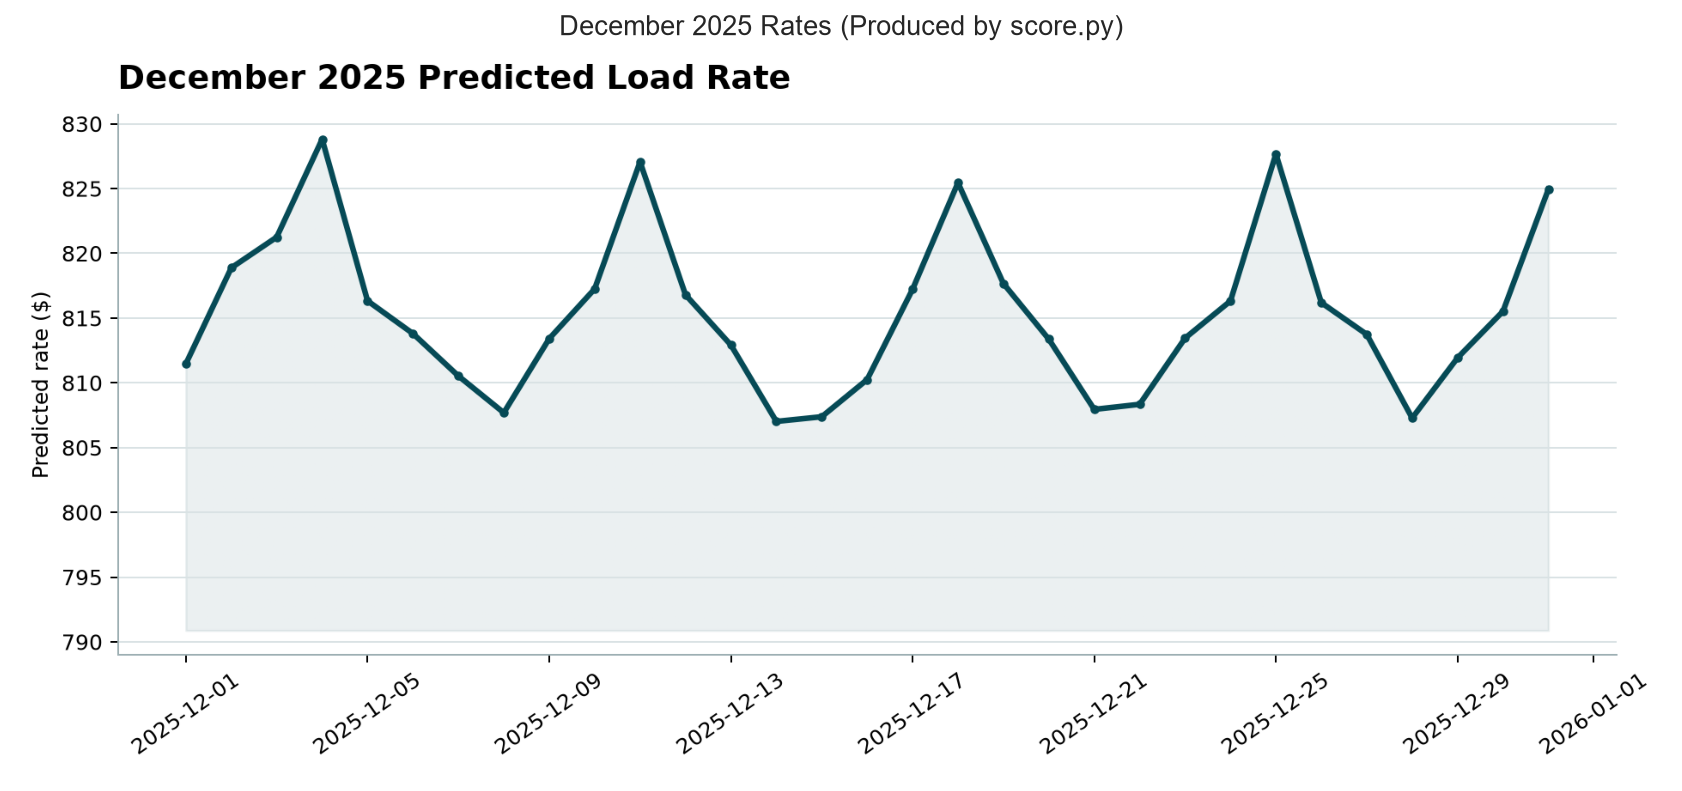

In [13]:
def run_scorer() -> None:
    print("=" * 72)
    print("RUNNING score.py VERIFICATION")
    print("=" * 72)
    cmd = [
        sys.executable,
        str(ROOT / "score.py"),
        "--predictions",
        str(PRED_PATH),
        "--december-predictions",
        str(DECEMBER_PRED_PATH),
        "--output-dir",
        str(SCORER_DIR),
    ]
    result = subprocess.run(cmd, check=True, capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)

run_scorer()

# Display the candidate December chart inline
candidate_chart = SCORER_DIR / "candidate_december.png"
if candidate_chart.is_file():
    img = plt.imread(str(candidate_chart))
    plt.figure(figsize=(11, 5), dpi=160)
    plt.imshow(img)
    plt.axis("off")
    plt.title("December 2025 Rates (Produced by score.py)", fontsize=12)
    plt.tight_layout()
    plt.show()